# Movie Recommendation System using Big Data Analytics
**Exploratory analysis and model evaluation notebook**

This notebook walks through the outputs of the PySpark pipeline that ran on **Google Cloud Dataproc** over the full **MovieLens 25M** dataset (25,000,095 ratings, 162,541 users, 62,423 movies).

| Layer | What it contains | Produced by |
|---|---|---|
| Bronze | Raw CSV converted to Parquet with explicit schemas and ingestion metadata | `src/bronze.py` |
| Silver | Cleaned, de-duplicated, typed data with a data-quality report | `src/silver.py` |
| Gold | Analysis-ready tables (movie stats, genre trends, user activity, KPIs) | `src/gold.py` |
| Output | ALS model, metrics, Top-10 recommendations, similar movies | `src/train_als.py` |

**Problem statement:** users face tens of thousands of titles and struggle to find movies they will enjoy. The goal is to learn each user's taste from historical ratings and recommend unseen movies they are likely to rate highly.

**Dataset:** F. Maxwell Harper and Joseph A. Konstan. 2015. *The MovieLens Datasets: History and Context.* ACM TiiS 5(4), Article 19. https://grouplens.org/datasets/movielens/25m/

> The heavy processing runs in Spark (`python run_pipeline.py` locally or `scripts/dataproc_run.ps1` on GCP). This notebook reads the resulting Parquet files from `data/` with pandas.

In [1]:
import glob, json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("..") / "data"
load = lambda rel: pd.read_parquet(DATA / rel)
metrics = json.loads(open(glob.glob(str(DATA / "output" / "metrics" / "part-*"))[0]).read())
print("Dataset:", metrics["dataset"])

Dataset: ml-25m


## 1. Pipeline: key PySpark transformations
The Silver layer de-duplicates repeated ratings with a window function, keeping each user's latest rating per movie:
```python
w = Window.partitionBy("userId", "movieId").orderBy(F.col("timestamp").desc())
ratings = ratings.withColumn("rn", F.row_number().over(w)).filter("rn = 1").drop("rn")
```
The Gold layer computes genre trends with Spark SQL and `LAG()`:
```sql
SELECT genre, rating_year, num_ratings,
       100.0 * (num_ratings - LAG(num_ratings) OVER (PARTITION BY genre ORDER BY rating_year))
             / LAG(num_ratings) OVER (PARTITION BY genre ORDER BY rating_year) AS yoy_growth_pct
FROM (SELECT genre, rating_year, COUNT(*) AS num_ratings FROM rating_genres GROUP BY genre, rating_year)
```
The model is Spark MLlib ALS, tuned over rank and regParam on a validation split:
```python
ALS(userCol="userId", itemCol="movieId", ratingCol="rating", rank=20, regParam=0.05,
    maxIter=10, nonnegative=True, coldStartStrategy="drop")
```

## 2. Data quality (Silver layer)
Every cleaning rule logs the rows before and after, so the cleaning is fully auditable.

In [2]:
load("silver/dq_report")

,table,check,rows_before,rows_after,removed
0,movies,null id/title,62423,62423,0
1,movies,duplicate movieId,62423,62423,0
2,ratings,null fields,25000095,25000095,0
3,ratings,invalid rating/timestamp,25000095,25000095,0
4,ratings,duplicate user-movie,25000095,25000095,0
5,ratings,orphan movieId,25000095,25000095,0
6,tags,null/empty tag,1093360,1093360,0
7,tags,duplicate tag,1093360,1093359,1


## 3. Platform activity over time

,rating_year,num_ratings,active_users,movies_rated,avg_rating,cumulative_ratings
20,2015,1604971,14262,25216,3.557,19041325
21,2016,1757440,14270,30847,3.531,20798765
22,2017,1689935,13252,33902,3.546,22488700
23,2018,1310761,12001,35877,3.564,23799461
24,2019,1200634,10601,41429,3.576,25000095


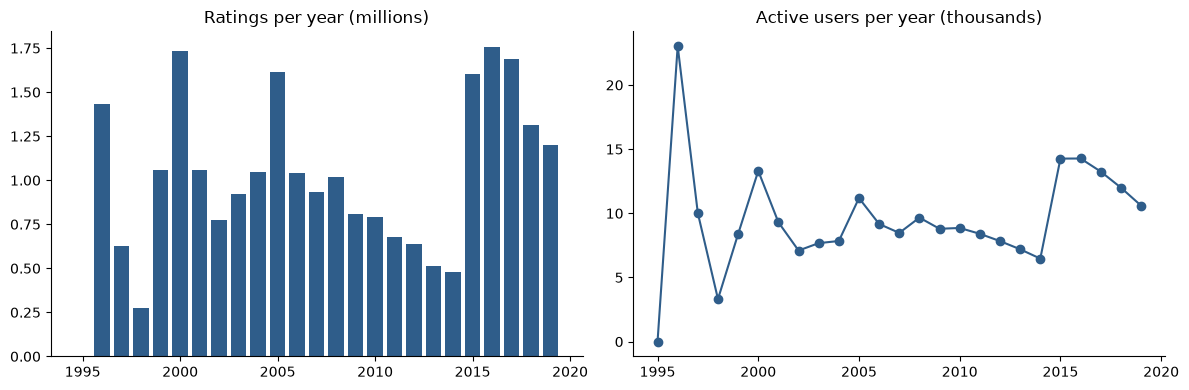

In [3]:
kpis = load("gold/yearly_kpis").sort_values("rating_year")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(kpis.rating_year, kpis.num_ratings / 1e6, color="#2F5D8A")
ax[0].set_title("Ratings per year (millions)")
ax[1].plot(kpis.rating_year, kpis.active_users / 1e3, marker="o", color="#2F5D8A")
ax[1].set_title("Active users per year (thousands)")
plt.tight_layout()
kpis.tail()

## 4. How do users rate?

49.8% of all ratings are 4 stars or higher


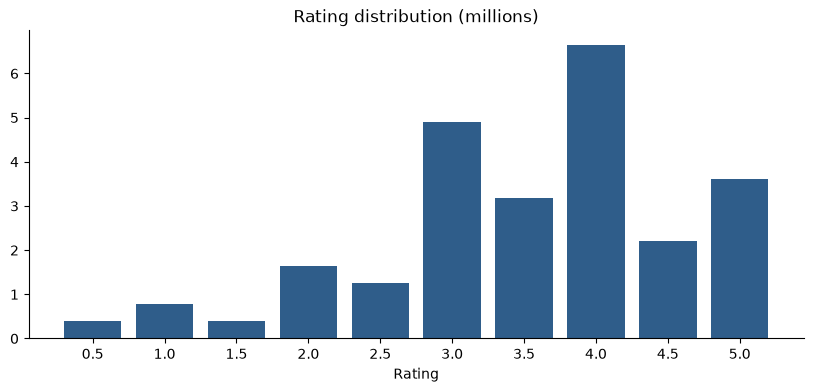

In [4]:
dist = load("gold/rating_distribution")
plt.bar(dist.rating.astype(str), dist["count"] / 1e6, color="#2F5D8A")
plt.title("Rating distribution (millions)")
plt.xlabel("Rating")
share = dist.loc[dist.rating >= 4, "count"].sum() / dist["count"].sum()
print(f"{share:.1%} of all ratings are 4 stars or higher")

## 5. Genre trends

,total_ratings,avg_rating
genre,,
Drama,10962833,3.679542
Comedy,8926230,3.412920
Action,7446918,3.469083
Thriller,6763272,3.541480
Adventure,5832424,3.522542
Romance,4497291,3.548292
Sci-Fi,4325740,3.473875
Crime,4190259,3.661840
Fantasy,2831585,3.516917


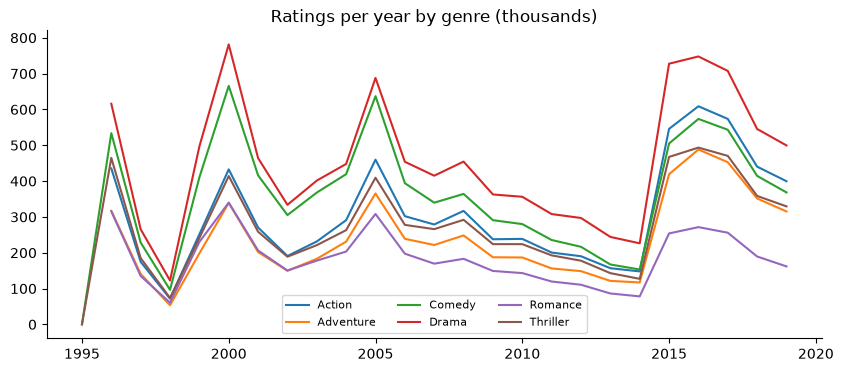

In [5]:
gt = load("gold/genre_trends")
top = gt.groupby("genre").num_ratings.sum().nlargest(6).index
for g, d in gt[gt.genre.isin(top)].sort_values("rating_year").groupby("genre"):
    plt.plot(d.rating_year, d.num_ratings / 1e3, label=g)
plt.legend(ncol=3, fontsize=8)
plt.title("Ratings per year by genre (thousands)")
gt.groupby("genre").agg(total_ratings=("num_ratings", "sum"), avg_rating=("avg_rating", "mean")) \
  .sort_values("total_ratings", ascending=False).head(10)

## 6. Best movies per genre (Bayesian weighted rating)
The weighted rating `WR = v/(v+m)·R + m/(v+m)·C` pulls movies with few ratings towards the global mean, so a film with three 5-star ratings cannot outrank an established classic.

In [6]:
tg = load("gold/top_movies_by_genre")
tg[tg.genre == "Sci-Fi"].sort_values("rank")[["rank", "clean_title", "release_year", "num_ratings", "avg_rating", "weighted_rating"]].head(10)

,rank,clean_title,release_year,num_ratings,avg_rating,weighted_rating
300,1,"Matrix, The",1999,72674,4.154,4.1511
301,2,Inception,2010,38895,4.156,4.1506
302,3,Star Wars: Episode V - The Empire Strikes Back,1980,57361,4.144,4.1404
303,4,Star Wars: Episode IV - A New Hope,1977,68717,4.120,4.1171
304,5,Blade Runner,1982,36702,4.116,4.1107
305,6,Interstellar,2014,22634,4.098,4.0897
306,7,"Prestige, The",2006,22943,4.093,4.0848
307,8,Eternal Sunshine of the Spotless Mind,2004,33225,4.066,4.0606
308,9,Nausicaä of the Valley of the Wind (Kaze no ta...,1984,5300,4.088,4.0546
309,10,Spider-Man: Into the Spider-Verse,2018,3085,4.111,4.0537


## 7. User segments

In [7]:
users = load("gold/user_activity")
seg = users.segment.value_counts()
print(seg.to_string())
users.num_ratings.describe().round(1)

segment
regular    60175
active     54179
casual     38474
power       9713


count    162541.0
mean        153.8
std         268.0
min          20.0
25%          36.0
50%          71.0
75%         162.0
max       32202.0
Name: num_ratings, dtype: float64

## 8. Model evaluation

In [8]:
grid = pd.DataFrame(metrics["grid"])
print(grid.to_string(index=False))
print()
for k in ["best_rank", "best_regParam", "movies_in_model", "test_rmse", "baseline_rmse_global_mean", "test_mae", "precision_at_10", "ndcg_at_10"]:
    print(f"{k:<28} {metrics[k]}")
print(f"\nRMSE improvement over baseline: {1 - metrics['test_rmse'] / metrics['baseline_rmse_global_mean']:.1%}")

 rank  regParam  val_rmse
   10      0.05    0.7998
   10      0.10    0.8139
   20      0.05    0.7913
   20      0.10    0.8115

best_rank                    20
best_regParam                0.05
movies_in_model              13176
test_rmse                    0.7874
baseline_rmse_global_mean    1.0578
test_mae                     0.6088
precision_at_10              0.0241
ndcg_at_10                   0.0308

RMSE improvement over baseline: 25.6%


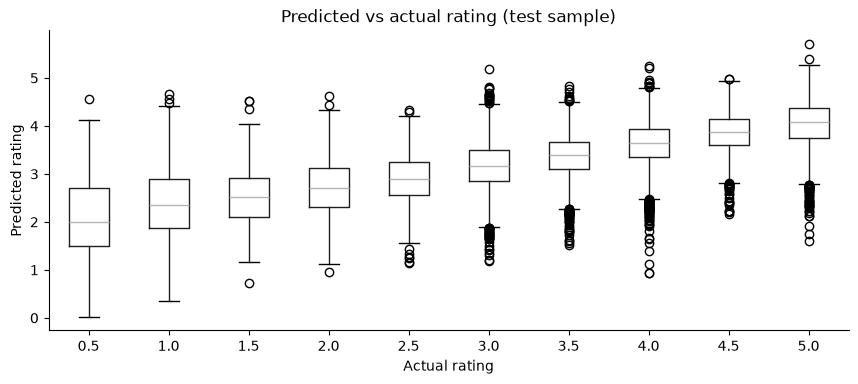

In [9]:
pred = load("output/test_predictions_sample")
pred.boxplot(column="prediction", by="rating", grid=False)
plt.suptitle("")
plt.title("Predicted vs actual rating (test sample)")
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating");

## 9. Recommendations for a user
Compare what a user loved with what the model recommends (movies they have not rated).

In [10]:
recs, fav = load("output/user_recs_top10"), load("gold/user_top_rated")
uid = 148
print("Favourites:")
print(fav[fav.userId == uid].sort_values("rank")[["clean_title", "rating"]].head(5).to_string(index=False))
print("\nRecommended:")
recs[recs.userId == uid].sort_values("rank")[["rank", "clean_title", "release_year", "predicted_rating"]]

Favourites:
                                                       clean_title  rating
                                                    Paths of Glory     5.0
Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il)     5.0
                                                         Chinatown     5.0
                               Life Is Beautiful (La Vita è bella)     5.0
                              Seven Samurai (Shichinin no samurai)     5.0

Recommended:


,rank,clean_title,release_year,predicted_rating
230,1,Planet Earth II,2016.0,4.540
231,2,Planet Earth,2006.0,4.533
232,3,Band of Brothers,2001.0,4.487
233,4,"In the blue sea, in the white foam.",1984.0,4.475
234,5,Life,2009.0,4.437
235,6,Cosmos,NaN,4.426
236,7,The Adventures of Sherlock Holmes and Dr. Wats...,1979.0,4.422
237,8,Alone in the Wilderness,2004.0,4.403
238,9,Blue Planet II,2017.0,4.310
239,10,Adventures Of Sherlock Holmes And Dr. Watson: ...,1986.0,4.298


## 10. Similar movies (cosine similarity on ALS item factors)

In [11]:
sim = load("output/similar_movies")
sim[sim.clean_title.str.startswith("Matrix, The")].sort_values("rank")[["rank", "similar_title", "similarity"]]

,rank,similar_title,similarity
1840,1,"Matrix Reloaded, The",0.879934
1841,2,Léon: The Professional (a.k.a. The Professiona...,0.873690
1842,3,Appleseed (Appurushîdo),0.869072
1843,4,"Usual Suspects, The",0.866817
1844,5,Fight Club,0.864263
1845,6,Twelve Monkeys (a.k.a. 12 Monkeys),0.862008
1846,7,Minority Report,0.861449
1847,8,Ninja Scroll (Jûbei ninpûchô),0.857897
1848,9,"Animatrix, The",0.856566
1849,10,"Professional, The (Le professionnel)",0.850390


## 11. Conclusions
- The pipeline cleans and processes 25M ratings on a 3-node Dataproc cluster in about 30 minutes end to end.
- Ratings skew positive, and activity peaks in the mid-2000s and again in 2015–2016.
- ALS cuts RMSE by about 26% compared with the global-mean baseline. Training only on movies with 50 or more ratings keeps recommendations relevant instead of surfacing obscure titles.
- Next steps: hybrid content features for cold-start movies, implicit-feedback ALS, and Spark Structured Streaming for real-time ratings.